# SENet — Squeeze-and-Excitation Networks

**Paper:** Hu, J., Shen, L., & Sun, G. (2018).  
*Squeeze-and-Excitation Networks.*  
IEEE Conference on Computer Vision and Pattern Recognition (CVPR 2018).  
arXiv:1709.01507. [[PDF]](https://arxiv.org/abs/1709.01507)

**Award:** ILSVRC 2017 Classification Winner (2.25% top-5 error).

---

## Overview

SENet introduces **channel attention**: a lightweight mechanism that explicitly models
interdependencies between channels, allowing the network to recalibrate feature responses
by selectively emphasising informative channels and suppressing less useful ones.

The SE block has two operations:
1. **Squeeze**: Global average pooling collapses spatial dimensions into a channel descriptor.
2. **Excitation**: Two FC layers learn a soft channel weighting vector (in [0,1] via Sigmoid).

The channel weights then multiply the original feature map — **no spatial complexity added**.

> 📄 **Paper:** Hu, Shen & Sun (2018). Squeeze-and-Excitation Networks. CVPR 2018.
> 🔗 **Link:** <https://arxiv.org/abs/1709.01507>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/senet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["ResNet stem /4"]:::stage --> S["SE-Bottleneck stages ×[3,4,6,3]"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph SE["Squeeze-and-Excitation on the residual branch"]
    direction LR
    U["U (C, H, W)"] --> SQ["squeeze: global avg pool → C"]:::block --> FC1["FC C → C/16 · ReLU"]:::block --> FC2["FC C/16 → C · sigmoid"]:::block
    FC2 --> SC["scale: U ⊙ s"]:::block
    U --> SC
  end
  S -.-> SE
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagrams (ASCII)

### SE Block
```
Feature map X [B, C, H, W]
        │
        ├─────────────────────────────────────┐  (identity)
        ▼                                     │
  GlobalAvgPool → [B, C, 1, 1]               │
        ▼                                     │
  Flatten → [B, C]                            │
        ▼                                     │
  FC(C → C//r) + ReLU  (r=16)                │
        ▼                                     │
  FC(C//r → C) + Sigmoid → s ∈ [0,1]^C       │
        ▼                                     │
  Reshape → [B, C, 1, 1]                      │
        └──────────────── × ──────────────────┘
                          ▼
               X̃ = X * s [B, C, H, W]
```

### SE Block inside ResNet Bottleneck
```
input ──────────────────────────────────── (+) ──→ ReLU
  │                                         ↑
  ▼                                         │
Conv 1×1 → BN → ReLU                       │
  ▼                                    (downsample if needed)
Conv 3×3 → BN → ReLU                       │
  ▼                                         │
Conv 1×1 → BN                              │
  ▼                                         │
SE Block (squeeze → excite → scale) ────────┘
```

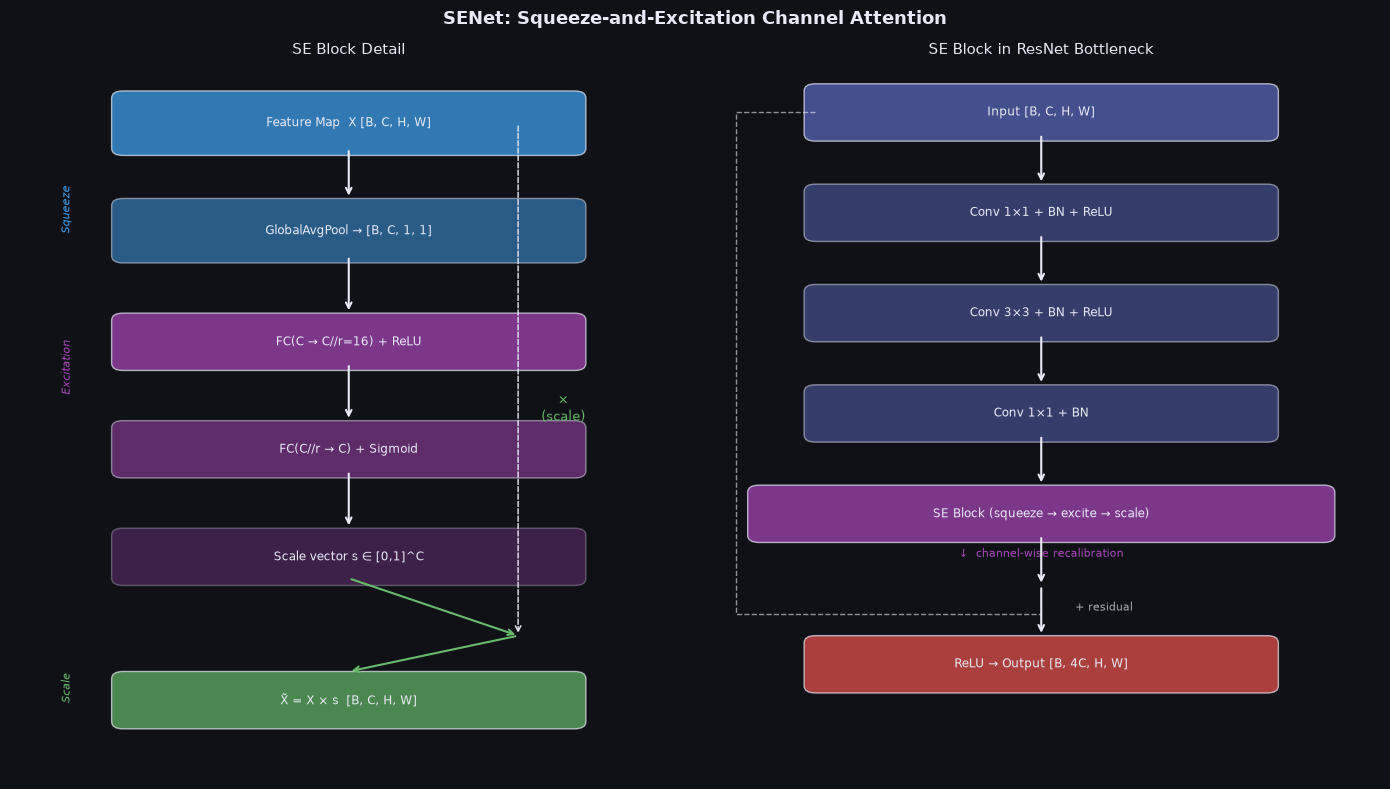

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

BG   = '#0f1117'
FG   = '#e8eaf6'
SQZ  = '#42a5f5'  # squeeze
EXC  = '#ab47bc'  # excitation
SCL  = '#66bb6a'  # scale
BLK  = '#ef5350'  # block output

fig, axes = plt.subplots(1, 2, figsize=(14, 8), facecolor=BG)
fig.suptitle('SENet: Squeeze-and-Excitation Channel Attention', color=FG, fontsize=13, fontweight='bold')

# ── Left: SE Block detail ─────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.set_xlim(0, 6); ax.set_ylim(0, 10); ax.axis('off')
ax.set_title('SE Block Detail', color=FG, fontsize=11)

def box(ax, x, y, w, h, text, color, alpha=0.7):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1', fc=color, alpha=alpha, ec=FG, lw=1))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', color=FG, fontsize=8.5)

def arr(ax, x, y1, y2):
    ax.annotate('', xy=(x, y2), xytext=(x, y1), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

box(ax, 1.0, 8.8, 4, 0.7, 'Feature Map  X [B, C, H, W]', SQZ)
arr(ax, 3.0, 8.8, 8.1)
box(ax, 1.0, 7.3, 4, 0.7, 'GlobalAvgPool → [B, C, 1, 1]', SQZ, 0.5)
ax.text(0.5, 7.65, 'Squeeze', ha='center', color=SQZ, fontsize=8, fontstyle='italic', rotation=90)
arr(ax, 3.0, 7.3, 6.5)
box(ax, 1.0, 5.8, 4, 0.6, 'FC(C → C//r=16) + ReLU', EXC)
arr(ax, 3.0, 5.8, 5.0)
box(ax, 1.0, 4.3, 4, 0.6, 'FC(C//r → C) + Sigmoid', EXC, 0.5)
ax.text(0.5, 5.4, 'Excitation', ha='center', color=EXC, fontsize=8, fontstyle='italic', rotation=90)
arr(ax, 3.0, 4.3, 3.5)
box(ax, 1.0, 2.8, 4, 0.6, 'Scale vector s ∈ [0,1]^C', EXC, 0.3)

# Multiply arrow
ax.annotate('', xy=(4.5, 2.0), xytext=(3.0, 2.8), arrowprops=dict(arrowstyle='->', color=SCL, lw=1.5))
ax.annotate('', xy=(4.5, 2.0), xytext=(4.5, 8.8+0.35), arrowprops=dict(arrowstyle='->', color=FG, lw=1, linestyle='dashed'))
ax.annotate('', xy=(3.0, 1.5), xytext=(4.5, 2.0), arrowprops=dict(arrowstyle='->', color=SCL, lw=1.5))
ax.text(4.9, 5.0, '×\n(scale)', ha='center', color=SCL, fontsize=9)

box(ax, 1.0, 0.8, 4, 0.6, 'X̃ = X × s  [B, C, H, W]', SCL)
ax.text(0.5, 1.1, 'Scale', ha='center', color=SCL, fontsize=8, fontstyle='italic', rotation=90)

# ── Right: SE inside Bottleneck ───────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.set_xlim(0, 6); ax2.set_ylim(0, 10); ax2.axis('off')
ax2.set_title('SE Block in ResNet Bottleneck', color=FG, fontsize=11)

RBLK = '#5c6bc0'
box(ax2, 1.0, 9.0, 4, 0.6, 'Input [B, C, H, W]', RBLK)
arr(ax2, 3.0, 9.0, 8.3)
box(ax2, 1.0, 7.6, 4, 0.6, 'Conv 1×1 + BN + ReLU', RBLK, 0.5)
arr(ax2, 3.0, 7.6, 6.9)
box(ax2, 1.0, 6.2, 4, 0.6, 'Conv 3×3 + BN + ReLU', RBLK, 0.5)
arr(ax2, 3.0, 6.2, 5.5)
box(ax2, 1.0, 4.8, 4, 0.6, 'Conv 1×1 + BN', RBLK, 0.5)
arr(ax2, 3.0, 4.8, 4.1)
box(ax2, 0.5, 3.4, 5, 0.6, 'SE Block (squeeze → excite → scale)', EXC)
ax2.text(3.0, 3.1, '↓  channel-wise recalibration', ha='center', color=EXC, fontsize=8)
arr(ax2, 3.0, 3.4, 2.7)

# Residual add
ax2.plot([1.0, 0.3, 0.3, 3.0], [9.3, 9.3, 2.3, 2.3], color=FG, lw=1, linestyle='dashed', alpha=0.6)
ax2.text(3.3, 2.35, '+ residual', color=FG, fontsize=8, alpha=0.7)
arr(ax2, 3.0, 2.7, 2.0)
box(ax2, 1.0, 1.3, 4, 0.6, 'ReLU → Output [B, 4C, H, W]', BLK)

plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations & Mathematics

### Squeeze Operation

The squeeze aggregates spatial information:
$$z_c = F_{sq}(\mathbf{u}_c) = \frac{1}{H \times W} \sum_{i=1}^{H} \sum_{j=1}^{W} u_c(i, j)$$

where $\mathbf{u}_c \in \mathbb{R}^{H \times W}$ is the $c$-th channel feature map.

### Excitation Operation

The excitation learns non-linear channel dependencies:
$$\mathbf{s} = F_{ex}(\mathbf{z}, \mathbf{W}) = \sigma(\mathbf{W}_2 \delta(\mathbf{W}_1 \mathbf{z}))$$

where $\delta$ is ReLU, $\sigma$ is Sigmoid, $\mathbf{W}_1 \in \mathbb{R}^{C/r \times C}$, $\mathbf{W}_2 \in \mathbb{R}^{C \times C/r}$.

### Scale Operation

$$\tilde{\mathbf{x}}_c = F_{scale}(\mathbf{u}_c, s_c) = s_c \cdot \mathbf{u}_c$$

### Parameter Overhead

SE block parameters: $\frac{2C^2}{r}$ per block.  For $C=256, r=16$: 8,192 parameters.  
SE-ResNet-50 adds ~2.5M params (~10%) over baseline ResNet-50.

### Reduction Ratio r

| r | Top-1 (ImageNet) | SE Params |
|---|-----------------|----------|
| 2 | 77.4% | +50% |
| 4 | 77.6% | +25% |
| **16** | **77.6%** | **+10%** |
| 32 | 77.4% | +5% |

r=16 is the optimal trade-off chosen in the paper.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/senet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/senet.py</code></summary>

```text
SENet / SE-ResNet Vision Backbones
=====================================

Implements SE-ResNet variants (Hu et al. 2018, "Squeeze-and-Excitation Networks",
CVPR 2018, ILSVRC 2017 classification winner).

Reference: https://arxiv.org/abs/1709.01507

Architecture
------------
Squeeze-and-Excitation (SE) adds a channel attention mechanism to residual blocks.
The SE block recalibrates channel-wise feature responses by:

  1. Squeeze:   GlobalAvgPool [B, C, H, W] → [B, C, 1, 1]
                Collapses spatial information into a channel descriptor.
  2. Excitation: Two FC layers with a bottleneck:
                 FC(C→C//r) → ReLU → FC(C//r→C) → Sigmoid → [B, C, 1, 1]
                 Learns non-linear channel interdependencies.
  3. Scale:     x × scale — multiplies the input feature map channel-wise.

The SE block is inserted after the last conv in a Bottleneck block (before the
residual addition), giving the network "self-recalibration" ability at each stage.

Parameter overhead: 2C²/r per block.  For C=256, r=16: ~8192 extra params per block.

Stage structure (same as ResNet-50/101/152):
  Stem    : 7×7 Conv + BN + ReLU + MaxPool (s2+s2) → 1/4 resolution
  Stage 0 : SEBottleneck × [3, 3, 3], 64 planes,  stride=1  → [B, 256,  H/4, W/4]
  Stage 1 : SEBottleneck × [4, 4, 4], 128 planes, stride=2  → [B, 512,  H/8, W/8]
  Stage 2 : SEBottleneck × [6,23,36], 256 planes, stride=2  → [B, 1024, H/16,W/16]
  Stage 3 : SEBottleneck × [3, 3, 3], 512 planes, stride=2  → [B, 2048, H/32,W/32]

SE-ResNeXt variant: replaces the grouped 3×3 conv in the bottleneck
  (cardinality C=32, base_width=4 for seresnext50_32x4d).

Registered names
----------------
  se_resnet50       — SEBottleneck × [3, 4, 6, 3],  embed_dim=2048
  se_resnet101      — SEBottleneck × [3, 4, 23, 3], embed_dim=2048
  se_resnet152      — SEBottleneck × [3, 8, 36, 3], embed_dim=2048
  seresnext50_32x4d — SE-ResNeXt (cardinality=32, base_width=4), embed_dim=2048

Citation
--------
  Hu, J., Shen, L., & Sun, G. (2018). Squeeze-and-Excitation Networks. CVPR.
  arXiv:1709.01507.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/senet.py`, definition by definition

**`SEBlock`** - Squeeze-and-Excitation channel attention block.

In [5]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention block.

    Reduces channels by reduction ratio r, then re-expands, producing a per-channel
    scaling vector in [0, 1] via Sigmoid. This vector multiplies the input features.

    Args:
        channels:  Input (and output) channel count.
        reduction: Squeeze ratio r.  Default 16 (original paper setting).
    """

    def __init__(self, channels: int, reduction: int = 16) -> None:
        super().__init__()
        squeezed = max(1, channels // reduction)
        self.pool = nn.AdaptiveAvgPool2d(1)
        # Two linear layers implemented as 1×1 convolutions (avoids reshape)
        self.fc1  = nn.Conv2d(channels, squeezed, kernel_size=1, bias=True)
        self.fc2  = nn.Conv2d(squeezed, channels, kernel_size=1, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Squeeze: global spatial average
        s = self.pool(x)                        # [B, C, 1, 1]
        # Excitation: FC → ReLU → FC → Sigmoid
        s = F.relu(self.fc1(s), inplace=True)   # [B, C//r, 1, 1]
        s = torch.sigmoid(self.fc2(s))          # [B, C,    1, 1]
        # Scale: channel-wise multiplication
        return x * s

**`SEBottleneck`** - ResNet Bottleneck with SE channel attention.

In [6]:
class SEBottleneck(nn.Module):
    """ResNet Bottleneck with SE channel attention.

    Architecture:
        input → Conv1×1 → BN → ReLU
              → Conv3×3 → BN → ReLU           (groups for ResNeXt variant)
              → Conv1×1 → BN
              → SE(reduction=16)               ← channel attention here
              → + residual → ReLU

    Args:
        in_planes:  Input channels.
        planes:     Bottleneck width (output = planes × 4).
        stride:     Applied to the 3×3 conv for spatial downsampling.
        downsample: 1×1 projection shortcut for shape matching.
        groups:     Convolution groups for the 3×3 (1=ResNet, 32=ResNeXt).
        base_width: Base channel width per group for ResNeXt scaling.
        reduction:  SE reduction ratio.
    """

    expansion: int = 4

    def __init__(
        self,
        in_planes:  int,
        planes:     int,
        stride:     int               = 1,
        downsample: Optional[nn.Module] = None,
        groups:     int               = 1,
        base_width: int               = 64,
        reduction:  int               = 16,
    ) -> None:
        super().__init__()
        # ResNeXt-style width scaling: actual mid-channels depend on groups + base_width
        width = int(planes * (base_width / 64.0)) * groups
        out_channels = planes * self.expansion

        # 1×1 reduce
        self.conv1 = nn.Conv2d(in_planes, width, kernel_size=1, bias=False)
        self.bn1   = nn.BatchNorm2d(width)

        # 3×3 spatial (with optional grouping for ResNeXt)
        self.conv2 = nn.Conv2d(width, width, kernel_size=3, stride=stride,
                               padding=1, groups=groups, bias=False)
        self.bn2   = nn.BatchNorm2d(width)

        # 1×1 expand
        self.conv3 = nn.Conv2d(width, out_channels, kernel_size=1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        # SE block applied to the expanded feature map
        self.se = SEBlock(out_channels, reduction=reduction)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))  # no activation before SE+add

        # SE recalibration before residual addition
        out = self.se(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out

**`SEResNet`** - SE-ResNet / SE-ResNeXt backbone.

In [7]:
class SEResNet(BaseVisionBackbone):
    """SE-ResNet / SE-ResNeXt backbone.

    Identical stage structure to ResNet-50/101/152 but uses SEBottleneck blocks.
    Returns 4-scale multi-resolution feature maps + global pooled embedding.

    Args:
        layers:     Number of SEBottleneck blocks per stage (4-element list).
        groups:     Convolution groups for 3×3 (1=SE-ResNet, 32=SE-ResNeXt).
        base_width: Base width per group (64=SE-ResNet, 4=se-resnext50_32x4d).
        reduction:  SE reduction ratio (default 16).
        img_size, in_chans, drop_rate, out_indices: See BaseVisionBackbone.
    """

    arch_name:    str       = "se_resnet"
    embed_dim:    int       = 2048
    feature_dims: list[int] = [256, 512, 1024, 2048]

    def __init__(
        self,
        layers:      list[int],
        groups:      int  = 1,
        base_width:  int  = 64,
        reduction:   int  = 16,
        img_size:    int  = 224,
        in_chans:    int  = 3,
        drop_rate:   float = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        self._groups     = groups
        self._base_width = base_width
        self._reduction  = reduction
        self._in_planes  = 64

        # ── Stem ─────────────────────────────────────────────────────────────
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # ── 4 residual stages ─────────────────────────────────────────────────
        self.stage0 = self._make_stage(64,  layers[0], stride=1)
        self.stage1 = self._make_stage(128, layers[1], stride=2)
        self.stage2 = self._make_stage(256, layers[2], stride=2)
        self.stage3 = self._make_stage(512, layers[3], stride=2)

        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]
        self._init_weights()

    def _make_stage(
        self,
        planes:   int,
        n_blocks: int,
        stride:   int,
    ) -> nn.Sequential:
        """Build one SE-ResNet stage."""
        out_channels = planes * SEBottleneck.expansion
        downsample   = None

        if stride != 1 or self._in_planes != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self._in_planes, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        blocks = [SEBottleneck(
            self._in_planes, planes, stride, downsample,
            groups=self._groups, base_width=self._base_width, reduction=self._reduction,
        )]
        self._in_planes = out_channels

        for _ in range(1, n_blocks):
            blocks.append(SEBottleneck(
                self._in_planes, planes,
                groups=self._groups, base_width=self._base_width, reduction=self._reduction,
            ))

        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        # Zero-init the last BN of each SEBottleneck's main branch for stable training
        for m in self.modules():
            if isinstance(m, SEBottleneck):
                nn.init.zeros_(m.bn3.weight)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run SE-ResNet forward pass.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, 2048]
              feature_maps  — strides [4, 8, 16, 32]: [B,256], [B,512], [B,1024], [B,2048]
        """
        x = self.stem(x)

        s0 = self.stage0(x)
        s1 = self.stage1(s0)
        s2 = self.stage2(s1)
        s3 = self.stage3(s2)

        pooled = self.dropout(self.pool(s3).flatten(1))

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0..stage (inclusive)."""
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`SEResNet50`** - SE-ResNet-50: SEBottleneck × [3,4,6,3], ~28M params, embed_dim=2048.

In [8]:
@register_vision_backbone("se_resnet50")
class SEResNet50(SEResNet):
    """SE-ResNet-50: SEBottleneck × [3,4,6,3], ~28M params, embed_dim=2048."""
    arch_name    = "se_resnet50"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 4, 6, 3], **kwargs)

**`SEResNet101`** - SE-ResNet-101: SEBottleneck × [3,4,23,3], ~49M params, embed_dim=2048.

In [9]:
@register_vision_backbone("se_resnet101")
class SEResNet101(SEResNet):
    """SE-ResNet-101: SEBottleneck × [3,4,23,3], ~49M params, embed_dim=2048."""
    arch_name    = "se_resnet101"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 4, 23, 3], **kwargs)

**`SEResNet152`** - SE-ResNet-152: SEBottleneck × [3,8,36,3], ~66M params, embed_dim=2048.

In [10]:
@register_vision_backbone("se_resnet152")
class SEResNet152(SEResNet):
    """SE-ResNet-152: SEBottleneck × [3,8,36,3], ~66M params, embed_dim=2048."""
    arch_name    = "se_resnet152"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 8, 36, 3], **kwargs)

**`SEResNeXt50_32x4d`** - SE-ResNeXt-50 (32×4d): cardinality=32, base_width=4, ~27M params.

In [11]:
@register_vision_backbone("seresnext50_32x4d")
class SEResNeXt50_32x4d(SEResNet):
    """SE-ResNeXt-50 (32×4d): cardinality=32, base_width=4, ~27M params."""
    arch_name    = "seresnext50_32x4d"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 4, 6, 3], groups=32, base_width=4, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [12]:
DEMOS = {"se_resnet50": 28.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['se_resnet101', 'se_resnet152', 'se_resnet50', 'seresnext50_32x4d']



se_resnet50  (SEResNet50)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 2048, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [13]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
se_resnet50              26.04M     28.09M    28.1M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [14]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

se_resnet50: loss 2.1634 | 223/223 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [15]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

se_resnet50: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

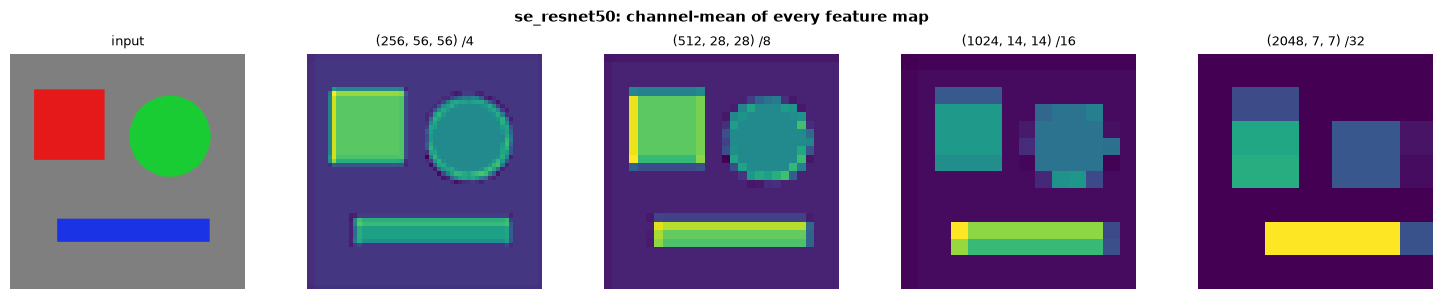

In [16]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [17]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [18]:
# ── Code Walkthrough ──────────────────────────────────────────────────────────
import torch

# 1. SE Block behaviour
se = SEBlock(channels=256, reduction=16)
x  = torch.randn(2, 256, 14, 14)
y  = se(x)
print('SEBlock(256, r=16):')
print(f'  Input:  {tuple(x.shape)}')
print(f'  Output: {tuple(y.shape)}  (same shape — only channel magnitudes change)')

# Show scale values are in [0,1]
with torch.no_grad():
    scale = torch.sigmoid(se.fc2(torch.relu(se.fc1(se.pool(x)))))
print(f'  Scale range: [{scale.min():.4f}, {scale.max():.4f}] ← should be in [0,1]')

# 2. SEBottleneck
blk = SEBottleneck(in_planes=256, planes=64)  # expansion → 256
print(f'\nSEBottleneck(256, 64):  params = {sum(p.numel() for p in blk.parameters()):,}')

SEBlock(256, r=16):
  Input:  (2, 256, 14, 14)
  Output: (2, 256, 14, 14)  (same shape — only channel magnitudes change)
  Scale range: [0.4319, 0.5695] ← should be in [0,1]

SEBottleneck(256, 64):  params = 78,864


In [19]:
# ── Usage Example ─────────────────────────────────────────────────────────────

for name in ['se_resnet50', 'se_resnet101', 'seresnext50_32x4d']:
    b = build_vision_backbone(name)
    b.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = b(x)
    print(f'{name}:')
    print(f'  pooled: {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params: {b.num_parameters():,}')

se_resnet50:
  pooled: (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params: 26,039,024


se_resnet101:
  pooled: (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params: 47,277,872


seresnext50_32x4d:
  pooled: (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params: 25,510,896


## References

| # | Citation |
|---|----------|
| [1] | Hu, J., Shen, L., & Sun, G. (2018). **Squeeze-and-Excitation Networks.** CVPR. arXiv:1709.01507. |
| [2] | He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Deep Residual Learning for Image Recognition.** CVPR. arXiv:1512.03385. |
| [3] | Woo, S., Park, J., Lee, J.-Y., & Kweon, I. S. (2018). **CBAM: Convolutional Block Attention Module.** ECCV. |
| [4] | Li, X., Wang, W., Hu, X., & Yang, J. (2019). **Selective Kernel Networks.** CVPR. |

---
*Notebook: SENet / SE-ResNet — HaleBlocks backbone family*  
*Architecture: `hale_core.nn.vision.cnn.senet`*